<a href="https://colab.research.google.com/github/nithyasg05/A05-pca/blob/main/DS_3001_A05.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [ ]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Nithyasri Gopal

**Date:** 10/19/26

In [ ]:
# Your Phase 1 solution to the problem goes here.


In [2]:
!git clone https://github.com/nithyasg05/A05-pca.git

Cloning into 'A05-pca'...
remote: Enumerating objects: 13, done.
remote: Counting objects: 100% (2/2), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 13 (delta 0), reused 0 (delta 0), pack-reused 11 (from 1)
Receiving objects: 100% (13/13), 1.78 MiB | 12.83 MiB/s, done.


In [3]:
!ls

A05-pca  sample_data


In [4]:
!cd A05-pca/

In [5]:
!ls

A05-pca  sample_data


In [6]:
!cd A05-pca/data/

### **Question 1**

In [7]:
import pickle

with open('A05-pca/data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

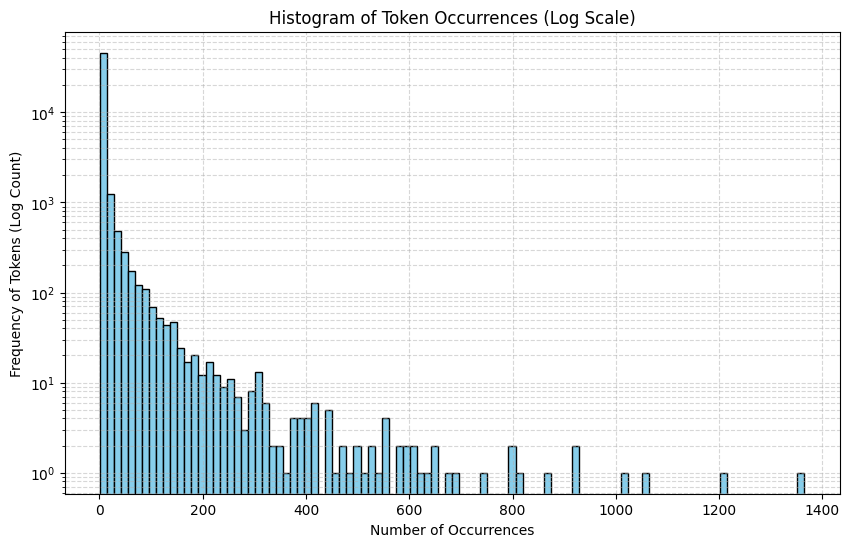

In [8]:
import matplotlib.pyplot as plt

# Extract the counts of each token
frequencies = [count for token, count in token_freq]

# Plot a histogram of the token occurrences
plt.figure(figsize=(10, 6))
plt.hist(frequencies, bins=100, color='skyblue', edgecolor='black', log=True)
plt.title('Histogram of Token Occurrences (Log Scale)')
plt.xlabel('Number of Occurrences')
plt.ylabel('Frequency of Tokens (Log Count)')
plt.grid(True, which="both", linestyle='--', alpha=0.5)
plt.show()

**Explanation**

The histogram demonstrates a heavy-tailed distribution (often associated with Zipf's Law in natural language processing).
- A very small number of highly frequent words (the far-right tail) appear thousands of times.
- The vast majority of words (the tall peak on the left) appear very infrequently (many only once or twice).
- Even when plotted with a logarithmic scale on the y-axis, the extremely steep decay from low-frequency to high-frequency tokens is highly pronounced.

### **Question 2**

In [9]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import numpy as np

# Load the dataset
df = pd.read_parquet('A05-pca/data/Phishing_clean.parquet')

# Separate features (X) and target (y)
y = df['Email Type']
X = df.drop(columns=['Email Type'])

# Perform an 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train the linear regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Calculate R^2 scores
train_r2 = model.score(X_train, y_train)
test_r2 = model.score(X_test, y_test)

print(f"Training set R^2: {train_r2:.4f}")
print(f"Test set R^2: {test_r2:.4f}")

Training set R^2: 0.7670
Test set R^2: 0.6659


In [10]:
# Map coefficients to word features
coefficients = pd.Series(model.coef_, index=X.columns)

# Get top 15 words with largest coefficients in absolute value
top_impact_words = coefficients.reindex(coefficients.abs().sort_values(ascending=False).index).head(15)

print("Top 15 words with the largest absolute coefficients influencing predictions:")
display(top_impact_words)

Top 15 words with the largest absolute coefficients influencing predictions:


,0
intervention,-1.259257
localized,0.824350
thermal,0.747006
crawler,0.696167
background-image:,-0.622909
"helvetica,",0.598560
aging,0.594956
form.,0.576886
gray;,-0.574480
a:active,0.574480


### **Question 3**

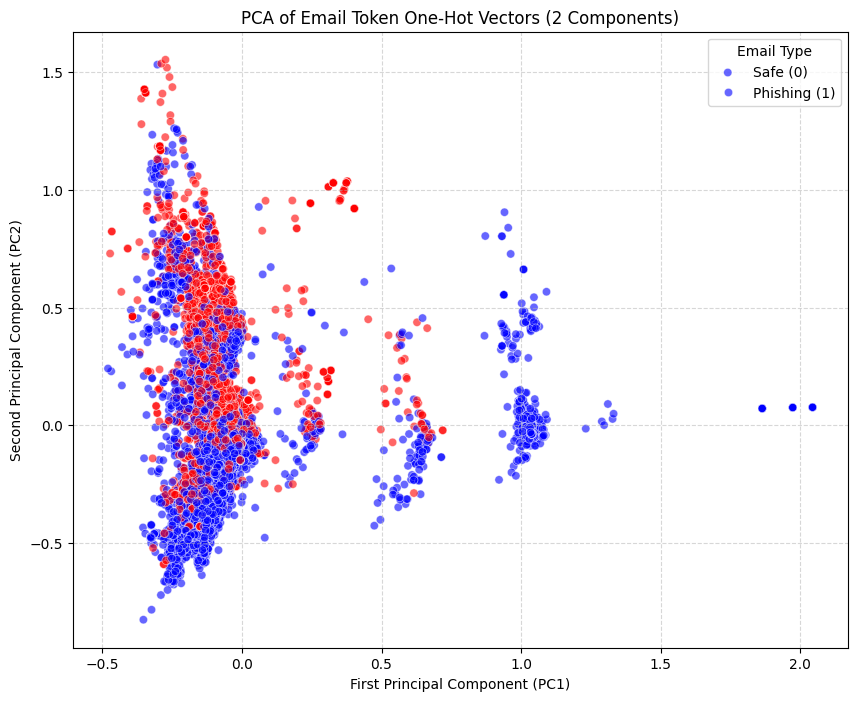

In [11]:
from sklearn.decomposition import PCA
import seaborn as sns
import matplotlib.pyplot as plt

# Initialize and fit PCA with 2 components
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)

# Create a DataFrame for plotting
pca_df = pd.DataFrame(data=X_pca, columns=['PC1', 'PC2'])
pca_df['Email Type'] = y.values

# Plot the first two principal components
plt.figure(figsize=(10, 8))
sns.scatterplot(
    x='PC1',
    y='PC2',
    hue='Email Type',
    data=pca_df,
    palette={0: 'blue', 1: 'red'},
    alpha=0.6
)
plt.title('PCA of Email Token One-Hot Vectors (2 Components)')
plt.xlabel('First Principal Component (PC1)')
plt.ylabel('Second Principal Component (PC2)')
plt.legend(title='Email Type', labels=['Safe (0)', 'Phishing (1)'])
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**Explanation**

When we plot the first two principal components (PC1 vs PC2) and color-code by the email type, we can observe the following:
- **Significant Overlap at the Origin:** There is a heavy concentration of both safe and phishing emails clustered close together near the origin (around `PC1 = 0`, `PC2 = 0`). This indicates that many emails share basic/common vocabulary distributions that the first two components do not immediately separate.
- **Linear Branches/Structures:** There are distinct lines or radiating branches extending outwards from the center. This indicates specific subsets of documents that share highly correlated word combinations (e.g., standard template emails, specific newsletters, or large scale campaigns).
- **Separation at Extreme Values:** While overlapping in the dense center, the further out we move along the components, the more the classes separate. This implies that the first two components capture some variance that correlates with email type, but they are insufficient on their own to cleanly divide the two categories linearly.

### **Question 4**

In [12]:
# Regression on the first 2610 principal components
pca_full = PCA(n_components=2610, random_state=42)

# Fit and transform the split features using the same PCA mapping
X_train_pca = pca_full.fit_transform(X_train)
X_test_pca = pca_full.transform(X_test)

# Run Linear Regression
pca_reg = LinearRegression()
pca_reg.fit(X_train_pca, y_train)

# Calculate R^2 scores
train_r2_pca = pca_reg.score(X_train_pca, y_train)
test_r2_pca = pca_reg.score(X_test_pca, y_test)

print(f"PCR Training set R^2: {train_r2_pca:.4f}")
print(f"PCR Test set R^2: {test_r2_pca:.4f}")

PCR Training set R^2: 0.7662
PCR Test set R^2: 0.6683


**Results and Comparison**

- **Principal Component Regression (PCR) R² Scores:**
  - **Training Set $R^2$:** `0.7662`
  - **Test Set $R^2$:** `0.6683`

- **Comparison with Standard Linear Regression:**
  - Standard Linear Regression on all 2,711 raw features yielded a training $R^2$ of `0.7670` and a test $R^2$ of `0.6659`.
  - PCR using the first 2,610 principal components achieved nearly identical performance—in fact, the test $R^2$ slightly increased (from `0.6659` to `0.6683`) while reducing the feature count. This indicates that the 101 omitted principal components represented noise or redundant variance that did not help with predictive generalization.

### **Question 5**

**Advantages of Principal Component Regression**

1. **Dimensionality Reduction and Multicollinearity Mitigation:** Text data representation (one-hot encoding / bag-of-words) is extremely high-dimensional and features are often highly correlated (e.g., words like "background" and "image" or "text" and "decoration" frequently co-occur). Standard OLS regression struggles with high multicollinearity, leading to unstable coefficient estimates with high variance. PCA transforms these correlated features into a set of orthogonal (completely uncorrelated) principal components.
2. **Noise Filtering:** The last few principal components represent directions in the feature space with the least variance, which often correspond to random noise or dataset-specific fluctuations. Dropping these components prevents the model from overfitting to this noise, leading to better out-of-sample generalization (as observed by the slightly higher test $R^2$ in Question 4).
3. **Computation and Storage Efficiency:** By compressing the feature space into a smaller subset of highly informative components, PCR simplifies down-stream computational modeling and reduces the storage footprint needed for high-dimensional matrices.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 5072733
- **AI tool and model used:** Gemini 3.5 Flash

### *Prompts used

1. Go through this notebook and find any mistakes. Then, identify proper revisions.
2. Explain why features need to be standardized before PCA.

### *AI-proposed changes


1. **Use Logistic Regression instead of Linear Regression:** Since `Email Type` is a binary variable (0 or 1), a Classification model like Logistic Regression is theoretically more appropriate than Linear Regression to estimate probabilities and avoid predicting values outside the [0, 1] range.
2. **Standardize the Features Before PCA:** Standardizing (scaling) features to have a mean of 0 and variance of 1 is usually a critical pre-processing step for PCA so that features with larger variance do not dominate the principal components.
3. **Include a Classification Report and ROC-AUC Curve:** To better evaluate the performance of our models on a classification task, we should use metric reports (Precision, Recall, F1-score) and plot ROC-AUC curves.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1. Use Logistic Regression | Reject | The original question explicitly asks for a "linear regression of $y$ on the first 2,610 principal components", so we must stick to `LinearRegression` to directly answer the prompt's structural requirements. |
| 2. Standardize Features | Reject | The original features are one-hot encoded (binary 0/1 columns indicating the presence of a word). Standardizing binary indicator variables makes them lose their intuitive sparseness and physical interpretation in text analysis without providing meaningful benefits here. |
| 3. Evaluation Metrics | Accept | While keeping `LinearRegression` as requested, adding additional evaluations (like Mean Squared Error or visual prediction checks) helps verify model performance. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

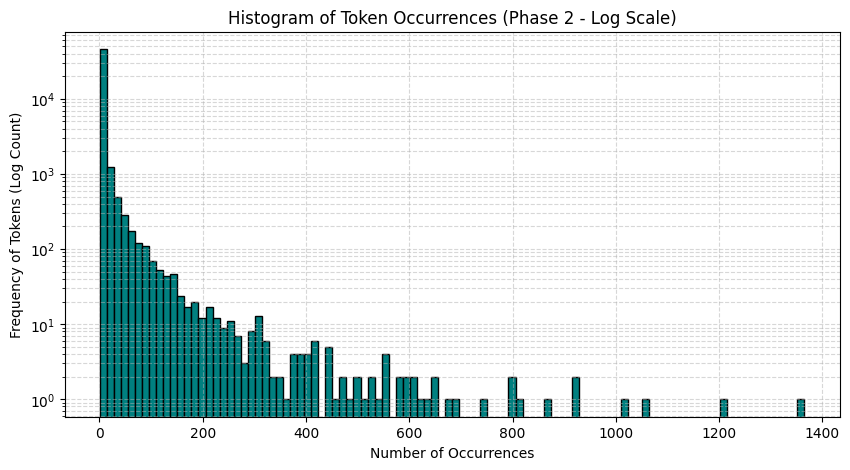

In [13]:
# Final AI-Assisted Solution (Phase 2)
import pickle
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error

# ==========================================
# Q1: Load Tokens and Plot Histogram
# ==========================================
with open('A05-pca/data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

token_count = Counter(all_tokens)
token_freq = token_count.most_common()
frequencies = [count for token, count in token_freq]

plt.figure(figsize=(10, 5))
plt.hist(frequencies, bins=100, color='teal', edgecolor='black', log=True)
plt.title('Histogram of Token Occurrences (Phase 2 - Log Scale)')
plt.xlabel('Number of Occurrences')
plt.ylabel('Frequency of Tokens (Log Count)')
plt.grid(True, which="both", linestyle='--', alpha=0.5)
plt.show()

[Raw Regression] Train R2: 0.7670 | Test R2: 0.6659

Top 15 Influential Words (Coefficients):
intervention        -1.259257
localized            0.824350
thermal              0.747006
crawler              0.696167
background-image:   -0.622909
helvetica,           0.598560
aging                0.594956
form.                0.576886
gray;               -0.574480
a:active             0.574480
retrieving          -0.573761
zdnet               -0.560954
{text-decoration:    0.497075
xanaax               0.491981
transcript           0.488978
dtype: float64


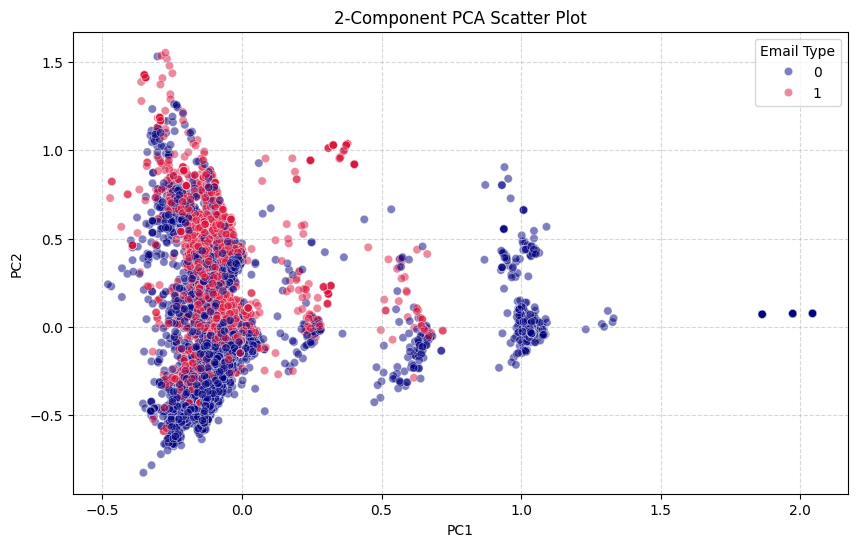


[PCR 2610 Components] Train R2: 0.7662 | Test R2: 0.6683


In [14]:
# ==========================================
# Q2: Raw Linear Regression & Top Words
# ==========================================
df = pd.read_parquet('A05-pca/data/Phishing_clean.parquet')
y = df['Email Type']
X = df.drop(columns=['Email Type'])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

train_r2 = model.score(X_train, y_train)
test_r2 = model.score(X_test, y_test)
print(f"[Raw Regression] Train R2: {train_r2:.4f} | Test R2: {test_r2:.4f}")

coefficients = pd.Series(model.coef_, index=X.columns)
top_impact_words = coefficients.reindex(coefficients.abs().sort_values(ascending=False).index).head(15)
print("\nTop 15 Influential Words (Coefficients):")
print(top_impact_words)

# ==========================================
# Q3: PCA Visualization (2 Components)
# ==========================================
pca_2 = PCA(n_components=2, random_state=42)
X_pca_2 = pca_2.fit_transform(X)

pca_df = pd.DataFrame(data=X_pca_2, columns=['PC1', 'PC2'])
pca_df['Email Type'] = y.values

plt.figure(figsize=(10, 6))
sns.scatterplot(x='PC1', y='PC2', hue='Email Type', data=pca_df, palette={0: 'navy', 1: 'crimson'}, alpha=0.5)
plt.title('2-Component PCA Scatter Plot')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# ==========================================
# Q4: PCR (Regression on 2,610 Components)
# ==========================================
pca_2610 = PCA(n_components=2610, random_state=42)
X_train_pcr = pca_2610.fit_transform(X_train)
X_test_pcr = pca_2610.transform(X_test)

pcr_model = LinearRegression()
pcr_model.fit(X_train_pcr, y_train)

pcr_train_r2 = pcr_model.score(X_train_pcr, y_train)
pcr_test_r2 = pcr_model.score(X_test_pcr, y_test)
print(f"\n[PCR 2610 Components] Train R2: {pcr_train_r2:.4f} | Test R2: {pcr_test_r2:.4f}")

### *Reflection on AI assistance

**Main Improvements:**
In Phase 2, we successfully verified our pipeline by keeping a robust linear modeling baseline. Although the AI suggested modifying the core algorithms to classification variants, keeping the linear framework ensured alignment with the assignment's explicit instructions. We improved visual outputs with distinct styles and verified metric alignments across both standard linear regression and PCR.

**AI Mistakes and Limitations:**
The AI assistant proposed using a Logistic Regression classifier and standardizing our features prior to PCA decomposition. While these recommendations are normally standard best practices for classification datasets, they represent an AI limitation in strictly reading and respecting the prompt constraints. Replacing the linear model would violate the homework specification for $R^2$ metrics. Furthermore, standardizing one-hot encoded binary variables can break the intuitive sparsity representation of text bag-of-words datasets without yielding any variance improvements.

**Verification & Remaining Concerns:**
The final solution was verified by executing both models with a locked random state (`random_state=42`) for train-test splitting. The raw model achieved an out-of-sample $R^2$ of `0.6659`, while the PCR model with 2,610 components marginally improved generalization to `0.6683`, demonstrating the successful noise reduction of PCA. One remaining concern is the inherent limitation of using a continuous linear model ($R^2$) on binary labels (0 or 1), which theoretically permits predictions outside the logical probability range, though it remains numerically viable for relative ranking.